# AgroInvest
## 01 - Exploración y preparación de datos

En este notebook se cargan y revisan los datasets principales del proyecto:
- Balance económico con precios constantes
- Balance económico con precios históricos
- Gastos de implantación tecnológica

In [2]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [6]:
df_constantes = pd.read_excel("Balance_economico.xlsx")

df_historicos = pd.read_excel(
    "Balance_economico_precios_distintos.xlsx"
)

df_inversiones = pd.read_excel(
    "gastos implantación tecnologia.xlsx"
)

In [8]:
print("Precios constantes:", df_constantes.shape)
print("Precios históricos:", df_historicos.shape)
print("Inversiones:", df_inversiones.shape)

Precios constantes: (105, 36)
Precios históricos: (105, 36)
Inversiones: (6, 2)


In [10]:
df_constantes.head()

,Año,Parcela,Cultivo,Superficie,GPS,RTK,ISOBUS,Siembra_variable,Abono_variable,Corte_tramos,Rend_t_ha,Precio_tonelada_venta,Humedad,Descuento_humedad_por_t,Ingreso_bruto_ha,Productividad_ha_h,Productividad_ha_12h,Consumo_L_h,Consumo_L_ha,Precio_litro_gasoleoB,Fitosanitarios_ha,Precio_litro_Fitosanitario,Semillas_ha,Semillas_min_ha,Semillas_max_ha,Precio_Semillas_ha,Abono_ha,Abono_min_ha,Abono_max_ha,Precio_Abono_kg,Pasadas_ha,Gastos_fijos_por_ha,Coste_total_por_ha,Coste_total_por_tonelada,Beneficio_por_ha,Beneficio_total_parcela
0,2020,Cerro Cruz Cati,Maiz,15.4,1,0,0,0,0,0,14.50,252.00,24.0,-25.634,3654.000,1.60,19.2,20.00,12.50,0.87603,4.25,72,102000,102000,102000,372.708,760,760,760,0.60,9,809.50,2414.454375,166.514095,1239.545625,19089.002625
1,2021,Cerro Cruz Cati,Maiz,15.4,1,1,1,1,1,1,16.12,252.00,18.0,-20.851,4062.240,1.90,22.8,19.32,10.20,0.87603,4.00,72,100000,91000,105000,365.400,700,650,770,0.60,9,809.50,2299.437674,142.645017,1762.802326,27147.155820
2,2023,Cerro Cruz Cati,Tomates,15.4,1,1,1,0,1,1,95.35,110.52,NaN,NaN,10538.082,1.30,15.6,23.60,18.88,0.87603,13.50,127,26000,26000,26000,1554.800,1350,1250,1450,0.65,15,2154.22,6549.111696,68.684968,3988.970304,61430.142682
3,2025,Cerro Cruz Cati,Maiz,15.4,1,1,1,1,0,1,15.90,252.00,22.0,-24.078,4006.800,1.85,22.2,19.50,10.54,0.87603,4.00,72,100000,91000,105000,365.400,760,760,760,0.60,9,809.50,2384.840406,149.989963,1621.959594,24978.177751
4,2026,Cerro Cruz Cati,Maiz,15.4,1,1,1,1,1,1,18.20,252.00,14.0,-9.230,4586.400,1.90,22.8,19.32,10.20,0.87603,4.00,72,100000,91000,105000,365.400,700,650,770,0.60,9,809.50,2131.305554,117.104701,2455.094446,37808.454468


In [12]:
df_historicos.head()

,Año,Parcela,Cultivo,Superficie,GPS,RTK,ISOBUS,Siembra_variable,Abono_variable,Corte_tramos,Rend_t_ha,Precio_tonelada_venta,Humedad,Descuento_humedad_por_t,Ingreso_bruto_ha,Productividad_ha_h,Productividad_ha_12h,Consumo_L_h,Consumo_L_ha,Precio_litro_gasoleoB,Fitosanitarios_ha,Precio_litro_Fitosanitario,Semillas_ha,Semillas_min_ha,Semillas_max_ha,Precio_Semillas_ha,Abono_ha,Abono_min_ha,Abono_max_ha,Precio_Abono_kg,Pasadas_ha,Gastos_fijos_por_ha,Coste_total_por_ha,Coste_total_por_tonelada,Beneficio_por_ha,Beneficio_total_parcela
0,2020,Cerro Cruz Cati,Maiz,15.4,1,0,0,0,0,0,14.50,220,24.0,-25.634,3190.0,1.60,19.2,20.00,12.50,0.6010,4.25,63,102000,102000,102000,307.02,760,760,760,0.42,9,669.50,2002.775500,138.122448,1187.224500,18283.257300
1,2021,Cerro Cruz Cati,Maiz,15.4,1,1,1,1,1,1,16.12,260,18.0,-20.851,4191.2,1.90,22.8,19.32,10.20,0.7101,4.00,72,100000,91000,105000,313.40,700,650,770,0.50,9,709.50,2062.205300,127.928368,2128.994700,32786.518380
2,2023,Cerro Cruz Cati,Tomates,15.4,1,1,1,0,1,1,95.35,150,NaN,NaN,14302.5,1.30,15.6,23.60,18.88,0.7704,13.50,120,26000,26000,26000,1430.00,1350,1250,1450,0.77,15,2044.22,6351.897280,66.616647,7950.602720,122439.281888
3,2025,Cerro Cruz Cati,Maiz,15.4,1,1,1,1,0,1,15.90,245,22.0,-24.078,3895.5,1.85,22.2,19.50,10.54,0.9621,4.00,74,100000,91000,105000,375.40,760,760,760,0.58,9,829.50,2415.805006,151.937422,1479.694994,22787.302908
4,2026,Cerro Cruz Cati,Maiz,15.4,1,1,1,1,1,1,18.20,250,14.0,-9.230,4550.0,1.90,22.8,19.32,10.20,1.2701,4.00,78,100000,91000,105000,380.00,700,650,770,0.64,9,869.50,2294.081180,126.048416,2255.918820,34741.149828


In [14]:
df_constantes.columns.tolist()

['Año',
 'Parcela',
 'Cultivo',
 'Superficie',
 'GPS',
 'RTK',
 'ISOBUS',
 'Siembra_variable',
 'Abono_variable',
 'Corte_tramos',
 'Rend_t_ha',
 'Precio_tonelada_venta',
 'Humedad',
 'Descuento_humedad_por_t',
 'Ingreso_bruto_ha',
 'Productividad_ha_h',
 'Productividad_ha_12h',
 'Consumo_L_h',
 'Consumo_L_ha',
 'Precio_litro_gasoleoB',
 'Fitosanitarios_ha',
 'Precio_litro_Fitosanitario',
 'Semillas_ha',
 'Semillas_min_ha',
 'Semillas_max_ha',
 'Precio_Semillas_ha',
 'Abono_ha',
 'Abono_min_ha',
 'Abono_max_ha',
 'Precio_Abono_kg',
 'Pasadas_ha',
 'Gastos_fijos_por_ha',
 'Coste_total_por_ha',
 'Coste_total_por_tonelada',
 'Beneficio_por_ha',
 'Beneficio_total_parcela']

In [16]:
df_constantes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Año                         105 non-null    int64  
 1   Parcela                     105 non-null    object 
 2   Cultivo                     105 non-null    object 
 3   Superficie                  105 non-null    float64
 4   GPS                         105 non-null    int64  
 5   RTK                         105 non-null    int64  
 6   ISOBUS                      105 non-null    int64  
 7   Siembra_variable            105 non-null    int64  
 8   Abono_variable              105 non-null    int64  
 9   Corte_tramos                105 non-null    int64  
 10  Rend_t_ha                   105 non-null    float64
 11  Precio_tonelada_venta       105 non-null    float64
 12  Humedad                     93 non-null     float64
 13  Descuento_humedad_por_t     93 non-

In [18]:
#limpieza
for df in [df_constantes, df_historicos]:
    df.columns = df.columns.str.strip()
    
    df["Parcela"] = df["Parcela"].astype(str).str.strip()
    df["Cultivo"] = df["Cultivo"].astype(str).str.strip()

In [20]:
df_constantes["Cultivo"].value_counts()

Cultivo
Maiz       51
Arroz      42
Tomates    12
Name: count, dtype: int64

In [24]:
sorted(df_constantes["Año"].unique())
#recordar que el año 2022 no se cuenta ya que hubo sequía en la zona por lo que no fue una campaña al uso ni normal

[2020, 2021, 2023, 2024, 2025, 2026]

In [26]:
#indicadir IIT
columnas_tecnologia = [
    "GPS",
    "RTK",
    "ISOBUS",
    "Siembra_variable",
    "Abono_variable",
    "Corte_tramos"
]

df_constantes["IIT"] = df_constantes[columnas_tecnologia].sum(axis=1)
df_historicos["IIT"] = df_historicos[columnas_tecnologia].sum(axis=1)

In [39]:
df_constantes["IIT"].value_counts().sort_index()

IIT
1    18
4     2
5    35
6    50
Name: count, dtype: int64

In [31]:
df_constantes[
    [
        "Año",
        "Parcela",
        "Cultivo",
        "GPS",
        "RTK",
        "ISOBUS",
        "Siembra_variable",
        "Abono_variable",
        "Corte_tramos",
        "IIT"
    ]
].head(10)

,Año,Parcela,Cultivo,GPS,RTK,ISOBUS,Siembra_variable,Abono_variable,Corte_tramos,IIT
0,2020,Cerro Cruz Cati,Maiz,1,0,0,0,0,0,1
1,2021,Cerro Cruz Cati,Maiz,1,1,1,1,1,1,6
2,2023,Cerro Cruz Cati,Tomates,1,1,1,0,1,1,5
3,2025,Cerro Cruz Cati,Maiz,1,1,1,1,0,1,5
4,2026,Cerro Cruz Cati,Maiz,1,1,1,1,1,1,6
5,2020,Tomillar,Maiz,1,0,0,0,0,0,1
6,2021,Tomillar,Maiz,1,1,1,1,1,1,6
7,2023,Tomillar,Maiz,1,1,1,0,1,0,4
8,2024,Tomillar,Tomates,1,1,1,0,1,1,5
9,2026,Tomillar,Maiz,1,1,1,1,1,1,6


In [33]:
#verificar que los dos excel representan las mismas observaciones técnicas
columnas_identificacion = [
    "Año",
    "Parcela",
    "Cultivo",
    "Superficie"
]

comparacion = (
    df_constantes[columnas_identificacion]
    == df_historicos[columnas_identificacion]
)

comparacion.all()

Año           True
Parcela       True
Cultivo       True
Superficie    True
dtype: bool

In [35]:
#ningun nulo
df_constantes.isnull().sum().sort_values(ascending=False)

Descuento_humedad_por_t       12
Humedad                       12
Año                            0
Abono_min_ha                   0
Semillas_ha                    0
Semillas_min_ha                0
Semillas_max_ha                0
Precio_Semillas_ha             0
Abono_ha                       0
Abono_max_ha                   0
Fitosanitarios_ha              0
Precio_Abono_kg                0
Pasadas_ha                     0
Gastos_fijos_por_ha            0
Coste_total_por_ha             0
Coste_total_por_tonelada       0
Beneficio_por_ha               0
Beneficio_total_parcela        0
Precio_litro_Fitosanitario     0
Consumo_L_ha                   0
Precio_litro_gasoleoB          0
Abono_variable                 0
Cultivo                        0
Superficie                     0
GPS                            0
RTK                            0
ISOBUS                         0
Siembra_variable               0
Corte_tramos                   0
Parcela                        0
Rend_t_ha 

In [37]:
df_historicos.isnull().sum().sort_values(ascending=False)

Descuento_humedad_por_t       12
Humedad                       12
Año                            0
Abono_min_ha                   0
Semillas_ha                    0
Semillas_min_ha                0
Semillas_max_ha                0
Precio_Semillas_ha             0
Abono_ha                       0
Abono_max_ha                   0
Fitosanitarios_ha              0
Precio_Abono_kg                0
Pasadas_ha                     0
Gastos_fijos_por_ha            0
Coste_total_por_ha             0
Coste_total_por_tonelada       0
Beneficio_por_ha               0
Beneficio_total_parcela        0
Precio_litro_Fitosanitario     0
Consumo_L_ha                   0
Precio_litro_gasoleoB          0
Abono_variable                 0
Cultivo                        0
Superficie                     0
GPS                            0
RTK                            0
ISOBUS                         0
Siembra_variable               0
Corte_tramos                   0
Parcela                        0
Rend_t_ha 

In [41]:
columnas_tecnicas = [
    "Año",
    "Parcela",
    "Cultivo",
    "Superficie",
    "GPS",
    "RTK",
    "ISOBUS",
    "Siembra_variable",
    "Abono_variable",
    "Corte_tramos",
    "Rend_t_ha",
    "Humedad",
    "Productividad_ha_h",
    "Productividad_ha_12h",
    "Consumo_L_h",
    "Consumo_L_ha",
    "Fitosanitarios_ha",
    "Semillas_ha",
    "Semillas_min_ha",
    "Semillas_max_ha",
    "Abono_ha",
    "Abono_min_ha",
    "Abono_max_ha",
    "Pasadas_ha"
]

In [43]:
comparacion_tecnica = (
    df_constantes[columnas_tecnicas]
    .fillna(-999)
    .equals(
        df_historicos[columnas_tecnicas]
        .fillna(-999)
    )
)

comparacion_tecnica

True

In [45]:
df_constantes["Escenario"] = "Precios constantes"
df_historicos["Escenario"] = "Precios históricos"

In [49]:
#crear el dataset económico conjunto
df_economico = pd.concat(
    [df_constantes, df_historicos],
    ignore_index=True
)

In [51]:
df_economico.shape

(210, 38)

In [53]:
df_economico["Escenario"].value_counts()

Escenario
Precios constantes    105
Precios históricos    105
Name: count, dtype: int64

In [55]:
resumen_cultivos = (
    df_constantes
    .groupby("Cultivo")
    .agg(
        Observaciones=("Cultivo", "size"),
        Superficie_media=("Superficie", "mean"),
        Rendimiento_medio=("Rend_t_ha", "mean"),
        Beneficio_medio_ha=("Beneficio_por_ha", "mean"),
        Consumo_medio_L_ha=("Consumo_L_ha", "mean"),
        IIT_medio=("IIT", "mean")
    )
    .round(2)
)

resumen_cultivos

,Observaciones,Superficie_media,Rendimiento_medio,Beneficio_medio_ha,Consumo_medio_L_ha,IIT_medio
Cultivo,,,,,,
Arroz,42,8.54,8.18,178.38,17.29,4.81
Maiz,51,11.23,16.03,1735.59,10.71,4.84
Tomates,12,8.26,106.45,5136.72,20.35,4.33


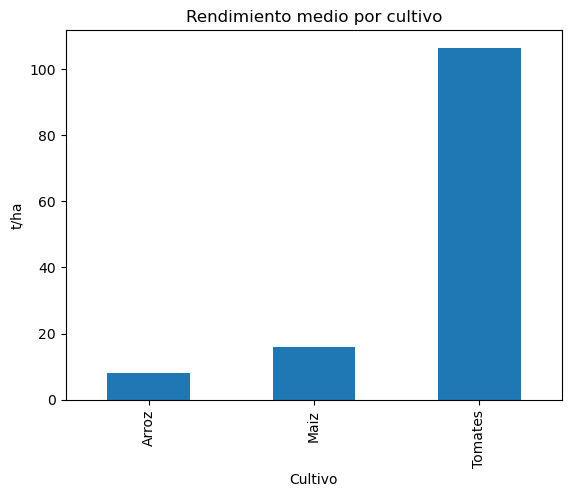

In [57]:
#rendimiento medio por cultivo
df_constantes.groupby("Cultivo")["Rend_t_ha"].mean().plot(
    kind="bar"
)

plt.title("Rendimiento medio por cultivo")
plt.ylabel("t/ha")
plt.xlabel("Cultivo")
plt.show()

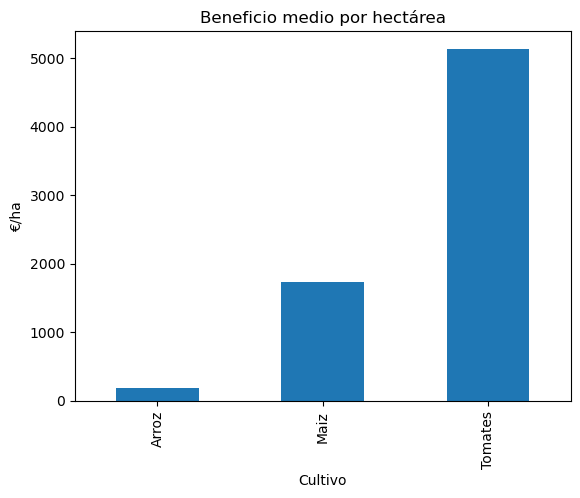

In [59]:
#beneficio medio por cultivo
df_constantes.groupby("Cultivo")["Beneficio_por_ha"].mean().plot(
    kind="bar"
)

plt.title("Beneficio medio por hectárea")
plt.ylabel("€/ha")
plt.xlabel("Cultivo")
plt.show()

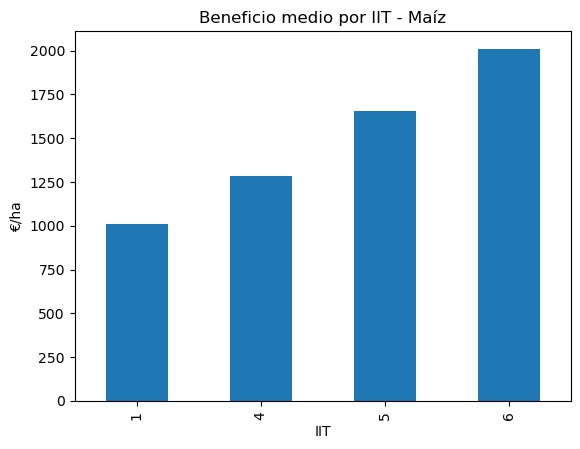

In [65]:
maiz = df_constantes[df_constantes["Cultivo"] == "Maiz"]

maiz.groupby("IIT")["Beneficio_por_ha"].mean().plot(
    kind="bar"
)

plt.title("Beneficio medio por IIT - Maíz")
plt.ylabel("€/ha")
plt.xlabel("IIT")
plt.show()

En maíz, el beneficio medio por hectárea aumenta de forma bastante clara con el IIT: aproximadamente desde unos 1.000 €/ha en IIT 1 hasta algo más de 2.000 €/ha en IIT 6. Visualmente parece una relación positiva fuerte entre mayor digitalización y mayor beneficio.

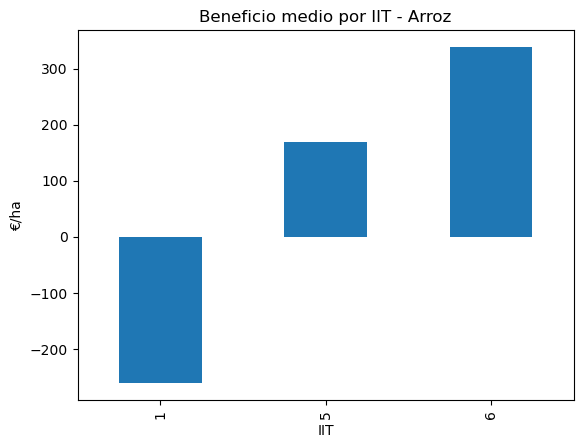

In [71]:
arroz = df_constantes[df_constantes["Cultivo"] == "Arroz"]

arroz.groupby("IIT")["Beneficio_por_ha"].mean().plot(
    kind="bar"
)

plt.title("Beneficio medio por IIT - Arroz")
plt.ylabel("€/ha")
plt.xlabel("IIT")
plt.show()

En arroz, la tendencia también es muy clara: con IIT 1 el beneficio medio es negativo, mientras que con IIT 5 y 6 pasa a ser positivo y creciente.

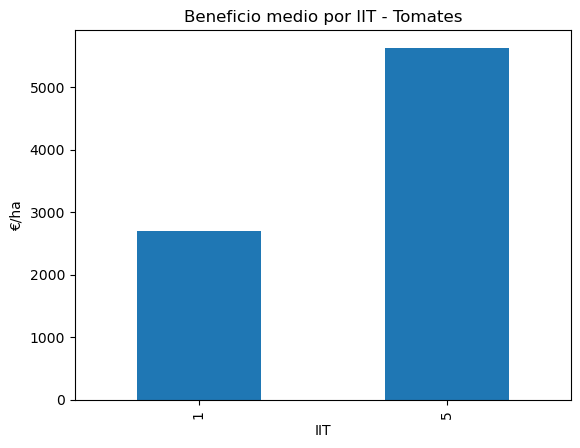

In [73]:
tomates = df_constantes[df_constantes["Cultivo"] == "Tomates"]

tomates.groupby("IIT")["Beneficio_por_ha"].mean().plot(
    kind="bar"
)

plt.title("Beneficio medio por IIT - Tomates")
plt.ylabel("€/ha")
plt.xlabel("IIT")
plt.show()

En tomate, también aparece una diferencia muy grande entre IIT 1 e IIT 5: el beneficio prácticamente se duplica. Aunque debemos ser prodentes debido al número reducido de observaciones

In [78]:
resumen_iit_cultivo = (
    df_constantes
    .groupby(["Cultivo", "IIT"])
    .agg(
        Observaciones=("Beneficio_por_ha", "size"),
        Beneficio_medio=("Beneficio_por_ha", "mean"),
        Beneficio_mediana=("Beneficio_por_ha", "median"),
        Beneficio_std=("Beneficio_por_ha", "std"),
        Rendimiento_medio=("Rend_t_ha", "mean"),
        Consumo_medio=("Consumo_L_ha", "mean")
    )
    .round(2)
)

resumen_iit_cultivo

Observaciones  Beneficio_medio  Beneficio_mediana  Beneficio_std  \
Cultivo IIT                                                                     
Arroz   1                7          -260.48            -241.57          57.36   
        5               15           169.92             145.30          97.05   
        6               20           338.32             330.40          90.46   
Maiz    1                9          1011.53            1006.48         116.24   
        4                2          1286.10            1286.10         280.51   
        5               10          1653.16            1674.00          84.20   
        6               30          2010.25            1899.07         306.88   
Tomates 1                2          2693.22            2693.22         234.45   
        5               10          5625.42            4889.71        1760.06   

             Rendimiento_medio  Consumo_medio  
Cultivo IIT                                    
Arroz   1                 7.20          20.00  
        5                 8.17          16.92  
        6                 8.53          16.61  
Maiz    1                13.43          12.50  
        4                14.42          11.14  
        5                15.91          10.54  
        6                16.96          10.20  
Tomates 1                87.50          27.70  
        5               110.24          18.88

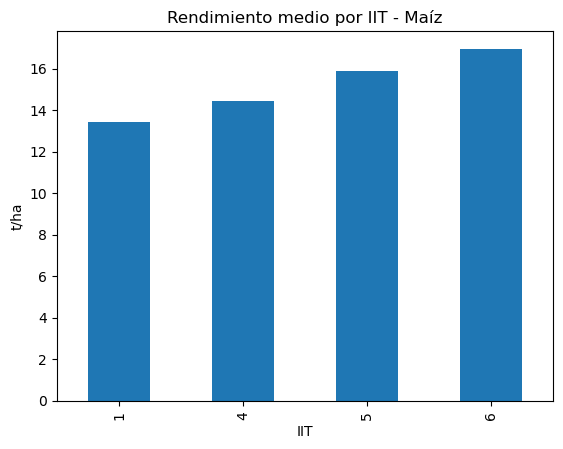

In [80]:
maiz.groupby("IIT")["Rend_t_ha"].mean().plot(kind="bar")
plt.title("Rendimiento medio por IIT - Maíz")
plt.ylabel("t/ha")
plt.xlabel("IIT")
plt.show()

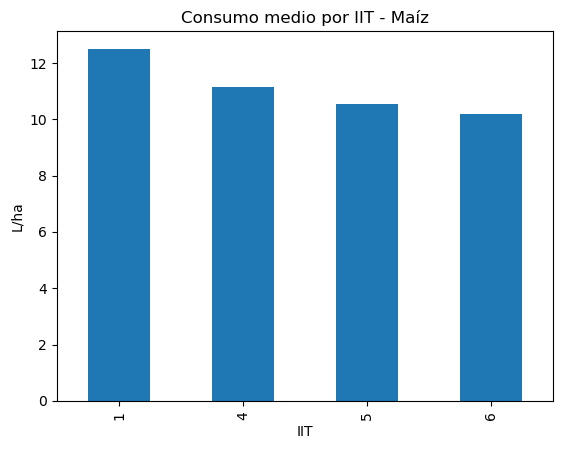

In [88]:
maiz.groupby("IIT")["Consumo_L_ha"].mean().plot(kind="bar")
plt.title("Consumo medio por IIT - Maíz")
plt.ylabel("L/ha")
plt.xlabel("IIT")
plt.show()

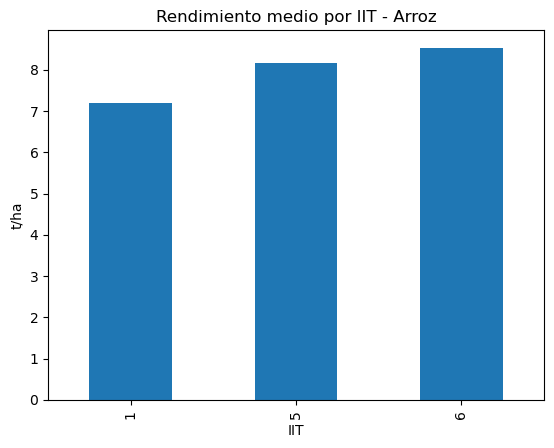

In [84]:
arroz.groupby("IIT")["Rend_t_ha"].mean().plot(kind="bar")
plt.title("Rendimiento medio por IIT - Arroz")
plt.ylabel("t/ha")
plt.xlabel("IIT")
plt.show()

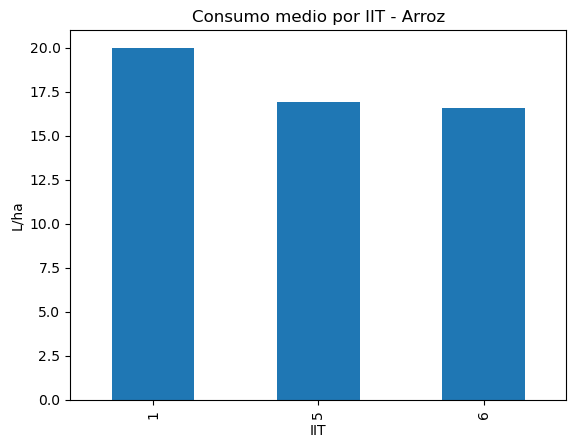

In [90]:
arroz.groupby("IIT")["Consumo_L_ha"].mean().plot(kind="bar")
plt.title("Consumo medio por IIT - Arroz")
plt.ylabel("L/ha")
plt.xlabel("IIT")
plt.show()

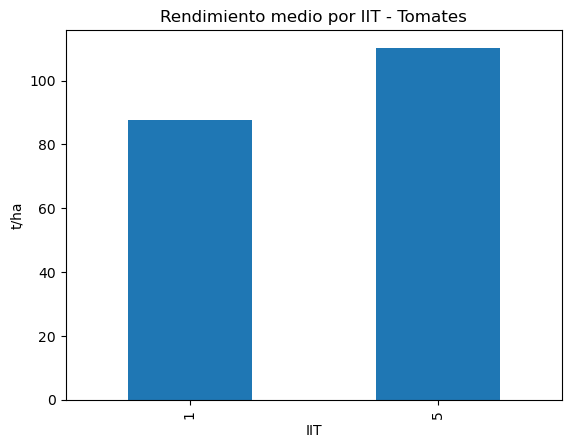

In [86]:
tomates.groupby("IIT")["Rend_t_ha"].mean().plot(kind="bar")
plt.title("Rendimiento medio por IIT - Tomates")
plt.ylabel("t/ha")
plt.xlabel("IIT")
plt.show()

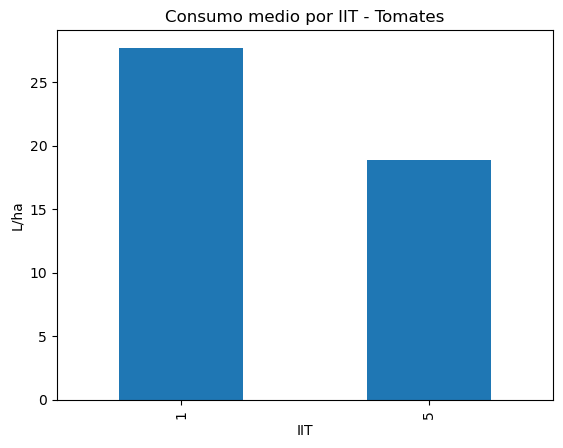

In [92]:
tomates.groupby("IIT")["Consumo_L_ha"].mean().plot(kind="bar")
plt.title("Consumo medio por IIT - Tomates")
plt.ylabel("L/ha")
plt.xlabel("IIT")
plt.show()

In [94]:
variables_eficiencia = [
    "Productividad_ha_h",
    "Fitosanitarios_ha",
    "Semillas_ha",
    "Abono_ha",
    "Pasadas_ha"
]

resumen_eficiencia = (
    df_constantes
    .groupby(["Cultivo", "IIT"])[variables_eficiencia]
    .mean()
    .round(2)
)

resumen_eficiencia

Productividad_ha_h  Fitosanitarios_ha  Semillas_ha  Abono_ha  \
Cultivo IIT                                                                 
Arroz   1                  1.10               4.75         32.0     760.0   
        5                  1.30               4.30         29.6     712.0   
        6                  1.38               4.00         28.0     700.0   
Maiz    1                  1.60               4.25     102000.0     760.0   
        4                  1.78               4.25     102000.0     700.0   
        5                  1.85               4.00     101400.0     718.0   
        6                  1.90               4.00     100000.0     700.0   
Tomates 1                  0.90              15.00      26000.0    1500.0   
        5                  1.30              13.50      26000.0    1365.0   

             Pasadas_ha  
Cultivo IIT              
Arroz   1          10.0  
        5          10.0  
        6          10.0  
Maiz    1           9.0  
        4           9.0  
        5           9.0  
        6           9.0  
Tomates 1          16.0  
        5          15.0

Comparación precios constantes vs precios históricos

In [97]:
comparacion_escenarios = (
    df_economico
    .groupby(["Cultivo", "Escenario"])
    .agg(
        Beneficio_medio_ha=("Beneficio_por_ha", "mean"),
        Coste_medio_ha=("Coste_total_por_ha", "mean"),
        Ingreso_medio_ha=("Ingreso_bruto_ha", "mean")
    )
    .round(2)
)

comparacion_escenarios

Beneficio_medio_ha  Coste_medio_ha  \
Cultivo Escenario                                                
Arroz   Precios constantes              178.38         2275.70   
        Precios históricos              823.88         2205.22   
Maiz    Precios constantes             1735.59         2304.46   
        Precios históricos             1821.08         2228.70   
Tomates Precios constantes             5136.72         6628.60   
        Precios históricos             5387.81         6368.48   

                            Ingreso_medio_ha  
Cultivo Escenario                             
Arroz   Precios constantes           2454.07  
        Precios históricos           3029.11  
Maiz    Precios constantes           4040.05  
        Precios históricos           4049.78  
Tomates Precios constantes          11765.31  
        Precios históricos          11756.29

In [99]:
comparacion_iit_escenario = (
    df_economico
    .groupby(["Cultivo", "IIT", "Escenario"])
    .agg(
        Beneficio_medio_ha=("Beneficio_por_ha", "mean")
    )
    .round(2)
)

comparacion_iit_escenario

Beneficio_medio_ha
Cultivo IIT Escenario                             
Arroz   1   Precios constantes             -260.48
            Precios históricos              286.30
        5   Precios constantes              169.92
            Precios históricos             1133.62
        6   Precios constantes              338.32
            Precios históricos              779.73
Maiz    1   Precios constantes             1011.53
            Precios históricos              993.34
        4   Precios constantes             1286.10
            Precios históricos             1833.94
        5   Precios constantes             1653.16
            Precios históricos             1962.02
        6   Precios constantes             2010.25
            Precios históricos             2021.57
Tomates 1   Precios constantes             2693.22
            Precios históricos              721.92
        5   Precios constantes             5625.42
            Precios históricos             6320.99

## Conclusión

El análisis exploratorio ha permitido validar la estructura y coherencia de los tres conjuntos de datos utilizados en AgroInvest: el balance económico con precios constantes, el balance con precios históricos y el fichero de costes de implantación tecnológica. Los dos balances contienen las mismas 105 observaciones agrícolas y las mismas variables técnicas, diferenciándose únicamente en los parámetros económicos y en los resultados derivados de ellos.

La muestra incluye tres cultivos —maíz, arroz y tomate— y distintos niveles de digitalización, representados mediante el Índice de Intensidad Tecnológica (IIT), calculado a partir de la presencia de GPS, RTK, ISOBUS, siembra variable, abonado variable y corte automático de tramos.

De forma descriptiva, se observa que los mayores niveles de IIT están asociados con mejores resultados productivos y económicos. En los tres cultivos analizados, los niveles tecnológicos superiores presentan, en general, mayores rendimientos, menor consumo de combustible por hectárea, mayor productividad y mayores beneficios por hectárea. También se observan reducciones en determinados insumos, como fertilizantes y fitosanitarios.

No obstante, estas relaciones deben interpretarse como asociaciones y no como efectos causales, ya que los datos proceden de observaciones reales y pueden estar influidos por otros factores como la campaña, la parcela, las condiciones agronómicas o las condiciones de mercado. Además, algunos grupos presentan un número reducido de observaciones, especialmente en tomate y en determinados niveles de IIT.

La comparación entre precios constantes y precios históricos confirma también que las condiciones de mercado pueden modificar de forma relevante los resultados económicos, por lo que resulta conveniente mantener ambos escenarios dentro de AgroInvest.

Tras esta fase exploratoria, los datos se consideran suficientemente preparados para avanzar hacia el análisis económico de inversiones, donde se estudiarán los costes de implantación tecnológica y se calcularán indicadores como ROI, Payback, VAN y TIR.